# Dataset audit — AI-assisted reproduction and conceptual walkthrough

This notebook reproduces the machine-verifiable claims in the unchanged
[`dataset_description.md`](../dataset_description.md). It uses the common raw CSV,
not a cleaned or reconstructed dataset. Comments and explanations are in English.

**Reading order:** concept → formula/denominator → calculation → interpretation.
The audit is descriptive: it does not train a predictor or establish clinical,
causal, psychometric, or data-generation validity. Missing values remain missing.

Sections 1–11 cover provenance, structure, types, participant profiles,
missingness, numeric summaries, target distribution, longitudinal variation,
temporal correlation, validity checks, and semantic flags. Section 12 compares
the published claims and exports the evidence. The extra sum-of-squares
decomposition is explicitly identified as an extension beyond the initial audit.

## 0. Locate the project and preserve the inputs

A reproducible calculation identifies both its input bytes and the software
environment. SHA-256 detects content differences; it cannot establish where the
file originated. Keep the original description and raw CSV unchanged. The
notebook locates the repository by its raw dataset path, so it can run from the
repository root or from this folder. Change `CSV_PATH` deliberately to inspect
another dataset; the loader rejects a different hash by default.

In [1]:
from pathlib import Path
import hashlib
import sys
import importlib.util
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

get_ipython().run_line_magic("matplotlib", "inline")
search_roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in search_roots if (p / "data/raw/Nicotine_Craving_Anxiety_Dynamics_30Days.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook within the repository and obtain the common raw CSV first; see data/README.md.")
AUDIT_DIR = ROOT / "work/andres/dataset_description/dataset_audit_AI_assisted"
spec = importlib.util.spec_from_file_location("dataset_audit", AUDIT_DIR / "audit.py")
audit = importlib.util.module_from_spec(spec)
spec.loader.exec_module(audit)
CSV_PATH = ROOT / "data/raw/Nicotine_Craving_Anxiety_Dynamics_30Days.csv"
OUTPUT = AUDIT_DIR / "results"
raw_hash_before = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
description_hash_before = hashlib.sha256(audit.ORIGINAL.read_bytes()).hexdigest()
df, metadata = audit.load_data(CSV_PATH)
report, tables = audit.run_audit(df, metadata)
display(pd.Series(metadata["environment"], name="version").to_frame())

,version
python,3.14.4
pandas,3.0.6
numpy,2.4.4


## 1. Provenance and CSV syntax (reference sections 1.1 and 1.9)

**File size** counts bytes, not observations. **SHA-256** hashes the file bytes;
the **Git blob identifier** hashes `b"blob " + byte_count + b"\0" + file_bytes`
with SHA-1. They identify the same content through different conventions.

The parser counts **logical CSV records**, allowing quoted fields, before pandas
reads the data. For each record, its field count must equal the header width.
This catches malformed rows that a permissive importer could otherwise obscure.
Literal empty cells and pandas-recognized NA cells are reported separately.
CSV values alone cannot prove the generator, licensing, or synthetic nature.

In [2]:
display(pd.Series(metadata["provenance"], name="value").to_frame())
syntax = metadata["csv_syntax"]
display(pd.Series({k: v for k, v in syntax.items() if k != "header"}, name="value").to_frame())
assert syntax["data_records"] == len(df)
assert metadata["provenance"]["matches_reference_sha256"]

,value
file_name,Nicotine_Craving_Anxiety_Dynamics_30Days.csv
size_bytes,4286125
sha256,7218b9c5925d3c4b69ef7dc0153861778f8a9e4deb67df...
git_blob_sha1,80bbba4a3289940698a2926618bf0f5f1525e69f
matches_reference_sha256,True
reference_document_sha256,22b299ed236c40024d40835a1fdc972f537a8fd39506b1...
audit_code_sha256,1204aef66e476349fd40fb3cc557c5c1514b1dff1106d9...
reference_values_sha256,55137001720f9a6eaeeab232ed48ee8a72b19482b6147b...
source_claim_scope,"Byte identity verified locally; origin, licens..."


,value
header_fields,35
duplicate_header_names,[]
data_records,30000
field_count_frequencies,{35: 30000}
malformed_records,0
malformed_examples,[]
literal_empty_cells,4982


## 2. Observation unit, panel balance, and duplicates (reference 1.2)

One row is a **simulated participant-day**, whereas a distinct participant is a
different counting unit. For participant $i$, let $n_i$ be its number of rows.
Equal $n_i$ is not sufficient to establish a balanced panel: repeated days could
hide missing days. We also require unique `(Participant_ID, Day_Number)` keys,
nonmissing keys, and the exact day set $\{1,\ldots,30\}$ for every participant.

`duplicate_keys_excess` counts additional copies after the first occurrence;
`rows_in_duplicate_keys` counts all rows belonging to repeated keys. Whole-row
duplicates are a separate issue. **Balanced keys do not imply complete cells or
independent measurements.** Thirty rows per participant are repeated observations.

In [3]:
display(pd.Series({k: v for k, v in report["structure"].items() if not isinstance(v, dict)}, name="value").to_frame())
display(tables["rows_per_participant"].head())
display(tables["rows_per_day"].T)
# Check exact day coverage rather than relying only on row counts.
day_sets = df.groupby("Participant_ID")["Day_Number"].agg(lambda s: set(s))
assert all(days == set(range(1, 31)) for days in day_sets)
assert not df.duplicated(audit.KEYS).any()

,value
rows,30000
columns,35
participants,1000
distinct_days,30
day_min,1
day_max,30
rows_per_person_min,30
rows_per_person_max,30
rows_per_day_min,1000
rows_per_day_max,1000


,rows
Participant_ID,
P0001,30
P0002,30
P0003,30
P0004,30
P0005,30


Day_Number,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
rows,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,...,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


## 3. Variable groups, storage types, and measurement meaning (reference 1.3 / Annex A)

A **storage dtype** describes representation, not scientific meaning. A score
stored as a float is not automatically a continuous validated clinical measure;
`First_Pouch_Time` is time-of-day text rather than a dated timestamp. Missing
values can make a conceptually integer field such as exercise minutes appear
as a floating-point column under ordinary NumPy-backed inference.

The original report lists 20 `float64`, 6 `int64`, and 9 `object` columns.
Pandas 3 instead infers a dedicated `str` dtype for text by default. We record
the native inference and explicitly read the nine known text columns as `object`
to reproduce the historical type table. Numeric values are not altered.
The five thematic groups are analytical groupings from the reference document.

In [4]:
display(pd.Series(report["structure"]["group_column_counts"], name="columns").to_frame())
display(pd.DataFrame({"native_count": metadata["reading_policy"]["native_dtype_counts"],
                      "historical_audit_count": metadata["reading_policy"]["audit_dtype_counts"]}).fillna(0).astype(int))
display(tables["inventory"][["group", "dtype", "native_dtype", "observed", "missing", "unique_observed", "min", "max"]])

,columns
Identification,2
Demographics,3
Nicotine and craving,15
Psychology,7
Habits and activities,8


,native_count,historical_audit_count
float64,20,20
str,9,0
int64,6,6
object,0,9


,group,dtype,native_dtype,observed,missing,unique_observed,min,max
column,,,,,,,,
Participant_ID,Identification,object,str,30000,0,1000,NaN,NaN
Day_Number,Identification,int64,int64,30000,0,30,1.0,30.0
Age_Group,Demographics,object,str,30000,0,5,NaN,NaN
Gender,Demographics,object,str,30000,0,4,NaN,NaN
Occupation_Status,Demographics,object,str,30000,0,6,NaN,NaN
Nicotine_Use_Duration_Months,Nicotine and craving,int64,int64,30000,0,86,3.0,120.0
Pouches_Per_Day,Nicotine and craving,int64,int64,30000,0,25,0.0,24.0
Pouch_Strength_mg,Nicotine and craving,int64,int64,30000,0,6,4.0,15.0
First_Pouch_Time,Nicotine and craving,object,str,30000,0,37,NaN,NaN


## 4. Stable participant profiles and categorical frequencies (reference 1.4–1.5)

For a supposedly stable profile field, count its distinct values **within each
participant**, including missingness as a possible distinct state. More than one
state flags a change; an all-missing profile still has to be detected separately
by the missingness audit. No changes across the four checked fields supports
counting one profile per participant.

For category $k$, its frequency is $f_k=\sum_i I(X_i=k)$ and its percentage is
$100f_k/N$. For demographics, $N=1{,}000$ participants. For daily indicators and
triggers, rows are participant-days. When a column has missing cells, report
both $N_{\mathrm{observed}}$ and $N_{\mathrm{total}}$: these answer different questions.
Missingness is not silently recoded as a category. Repeated participant-day
frequencies do not estimate population prevalence.

In [5]:
profile_states = df.groupby("Participant_ID")[audit.PROFILE].nunique(dropna=False)
display(profile_states.gt(1).sum().rename("participants_with_changes").to_frame())
assert not profile_states.gt(1).any().any()
freq = tables["categorical_frequencies"]
display(freq[freq["unit"].eq("participant")])
display(freq[freq["variable"].isin(["Craving_Triggers", "Major_Stress_Event_Today"])].sort_values(["variable", "count"], ascending=[True, False]))

,participants_with_changes
Age_Group,0
Gender,0
Occupation_Status,0
Nicotine_Use_Duration_Months,0


,variable,category,unit,count,observed_denominator,total_denominator,percent_observed,percent_total
0,Age_Group,18-24,participant,239,1000,1000,23.9,23.9
1,Age_Group,25-34,participant,353,1000,1000,35.3,35.3
2,Age_Group,35-44,participant,203,1000,1000,20.3,20.3
3,Age_Group,45-54,participant,122,1000,1000,12.2,12.2
4,Age_Group,55+,participant,83,1000,1000,8.3,8.3
5,Gender,Female,participant,482,1000,1000,48.2,48.2
6,Gender,Male,participant,453,1000,1000,45.3,45.3
7,Gender,Non-binary,participant,41,1000,1000,4.1,4.1
8,Gender,Prefer_not_to_say,participant,24,1000,1000,2.4,2.4
9,Occupation_Status,Employed,participant,488,1000,1000,48.8,48.8


,variable,category,unit,count,observed_denominator,total_denominator,percent_observed,percent_total
23,Craving_Triggers,Stress,participant-day,6077,29677,30000,20.477137,20.256667
17,Craving_Triggers,Boredom,participant-day,3505,29677,30000,11.810493,11.683333
20,Craving_Triggers,Morning,participant-day,2960,29677,30000,9.974054,9.866667
15,Craving_Triggers,After_Meal,participant-day,2955,29677,30000,9.957206,9.850000
26,Craving_Triggers,Work,participant-day,2925,29677,30000,9.856118,9.750000
22,Craving_Triggers,Social_Situation,participant-day,2413,29677,30000,8.130876,8.043333
19,Craving_Triggers,Habit,participant-day,2390,29677,30000,8.053375,7.966667
24,Craving_Triggers,Study,participant-day,2363,29677,30000,7.962395,7.876667
25,Craving_Triggers,Withdrawal,participant-day,1430,29677,30000,4.818546,4.766667
18,Craving_Triggers,Caffeine,participant-day,1182,29677,30000,3.982882,3.940000


## 5. Missing cells, incomplete rows, and incomplete columns (reference 1.7)

Define $M_{ij}=1$ when row $i$, column $j$ is missing. Then:

- Missing cells: $\sum_i\sum_j M_{ij}$; percentage denominator is $np$ cells.
- Missing in column $j$: $m_j=\sum_i M_{ij}$; percentage denominator is $n$ rows.
- Incomplete rows: $\sum_i I(\sum_j M_{ij}>0)$; percentage denominator is $n$ rows.
- Incomplete columns: $\sum_j I(m_j>0)$; complete columns have $m_j=0$.

One row can have several missing cells, so cell and row totals should differ.
A present participant-day can have an absent target: **a missing value is not a
missing key**. A small cell percentage does not establish MCAR/MAR/MNAR or justify
automatic zero imputation. Per-column summaries use all observed cells in that
column, not a blanket complete-case deletion of every incomplete row.

In [6]:
missing_mask = df.isna()
cell_count = int(missing_mask.to_numpy().sum())
incomplete_rows = int(missing_mask.any(axis=1).sum())
display(pd.Series({
    "missing_cells": cell_count,
    "all_cells": df.size,
    "missing_cell_percent": 100 * cell_count / df.size,
    "incomplete_rows": incomplete_rows,
    "all_rows": len(df),
    "incomplete_row_percent": 100 * incomplete_rows / len(df),
    "literal_empty_cells_in_raw_csv": syntax["literal_empty_cells"],
}, name="value").to_frame())
display(tables["missing_by_column"].query("missing > 0").sort_values("missing", ascending=False))
display(missing_mask.sum(axis=1).value_counts().sort_index().rename_axis("missing_cells_in_row").rename("rows").to_frame())
assert cell_count == syntax["literal_empty_cells"]

,value
missing_cells,4.982000e+03
all_cells,1.050000e+06
missing_cell_percent,4.744762e-01
incomplete_rows,4.630000e+03
all_rows,3.000000e+04
incomplete_row_percent,1.543333e+01
literal_empty_cells_in_raw_csv,4.982000e+03


,missing,observed,percent_rows
column,,,
Longest_Nicotine_Free_Period_Hours,380,29620,1.266667
Afternoon_Cravings_Score,373,29627,1.243333
Screen_Time_Hours,373,29627,1.243333
Exercise_Minutes,370,29630,1.233333
Morning_Cravings_Score,369,29631,1.230000
Successfully_Resisted,357,29643,1.190000
Time_Since_Last_Pouch_Minutes,355,29645,1.183333
Social_Interaction_Hours,353,29647,1.176667
Overall_Craving_Score,349,29651,1.163333


,rows
missing_cells_in_row,
0,25370
1,4293
2,323
3,13
4,1


## 6. Location, dispersion, and observed range (reference 1.5–1.6)

For observed numeric values $x_1,\ldots,x_N$:

| Quantity | Definition and interpretation |
| --- | --- |
| Observed $N$ | Number of available values; excludes missing cells |
| Minimum / maximum | Smallest / largest observed value; not a documented allowable range |
| Mean | $\bar x=\frac{1}{N}\sum_j x_j$; uses magnitudes and is sensitive to extremes |
| Median | Middle sorted value, or mean of the two middle values for even $N$ |
| Sample variance | $s^2=\frac{1}{N-1}\sum_j(x_j-\bar x)^2$; squared score units |
| Sample standard deviation | $s=\sqrt{s^2}$; same units as the measurements |
| Q1 / Q3 | 25th / 75th percentiles using linear interpolation |
| IQR | $Q_3-Q_1$; width of the central half of the empirical distribution |

**Why `ddof=1`?** It reproduces the published sample standard deviation rather
than the population formula with divisor $N$. It does not make the repeated
measurements independent, and it is not the standard error of the mean.

For a quantile at probability $p$, sort the observed values as $x_{(0)},\ldots,
x_{(N-1)}$, calculate $h=(N-1)p$, $j=\lfloor h\rfloor$, and
$Q(p)=x_{(j)}+(h-j)(x_{(\lceil h\rceil)}-x_{(j)})$.
Quartile conventions can differ, so the interpolation rule is explicit.

In [7]:
x = df[audit.TARGET].dropna().to_numpy(dtype=float)
observed_n = len(x)
mean_manual = sum(x) / observed_n
squared_deviations = sum((value - mean_manual) ** 2 for value in x)
variance_manual = squared_deviations / (observed_n - 1)
std_manual = math.sqrt(variance_manual)
sorted_x = sorted(x)

def linear_quantile(values, probability):
    position = (len(values) - 1) * probability
    lower, upper = math.floor(position), math.ceil(position)
    return values[lower] + (position - lower) * (values[upper] - values[lower])

manual_summary = pd.Series({
    "observed": observed_n, "min": min(x), "max": max(x),
    "mean": mean_manual, "median": linear_quantile(sorted_x, 0.5),
    "sample_variance": variance_manual, "sample_std": std_manual,
    "q1": linear_quantile(sorted_x, 0.25), "q3": linear_quantile(sorted_x, 0.75),
    "iqr": linear_quantile(sorted_x, 0.75) - linear_quantile(sorted_x, 0.25),
})
display(manual_summary.rename("manual_target_value").to_frame())
display(tables["numeric_summary"])
assert math.isclose(std_manual, report["target"]["sample_std"], abs_tol=1e-12)

,manual_target_value
observed,29651.000000
min,0.000000
max,10.000000
mean,5.994904
median,6.000000
sample_variance,2.837220
sample_std,1.684405
q1,4.800000
q3,7.200000
iqr,2.400000


,observed,missing,min,max,mean,median,sample_variance,sample_std,q1,q3,iqr
column,,,,,,,,,,,
Day_Number,30000,0,1.0,30.0,15.500000,15.5,74.919164,8.655586,8.0,23.0,15.0
Nicotine_Use_Duration_Months,30000,0,3.0,120.0,21.592000,16.0,330.716560,18.185614,9.0,29.0,20.0
Pouches_Per_Day,30000,0,0.0,24.0,7.430900,7.0,18.813786,4.337486,4.0,10.0,6.0
Pouch_Strength_mg,30000,0,4.0,15.0,7.859367,8.0,7.288032,2.699636,6.0,10.0,4.0
Time_Since_Last_Pouch_Minutes,29645,355,5.0,716.0,73.512768,43.0,9212.610593,95.982345,11.0,95.0,84.0
Longest_Nicotine_Free_Period_Hours,29620,380,1.0,23.9,6.202465,6.0,10.002090,3.162608,4.0,8.1,4.1
Morning_Cravings_Score,29631,369,0.0,10.0,5.542611,5.5,2.563615,1.601129,4.5,6.6,2.1
Afternoon_Cravings_Score,29627,373,0.0,10.0,6.333122,6.3,2.942641,1.715413,5.2,7.5,2.3
Evening_Cravings_Score,29654,346,0.4,10.0,5.806886,5.8,2.579464,1.606071,4.7,6.9,2.2


## 7. Histogram and target availability (reference 1.6)

Each histogram frequency counts observed target values in a predefined interval.
Use $[0,1),[1,2),\ldots,[8,9),[9,10]$: an exact 6 belongs to $[6,7)$ and an exact
10 belongs to the final bin. Exclude missing targets from bin counts and divide
bin percentages by observed $N$, not all 30,000 rows. Availability percentages
use all rows. Verify that the bins cover every observed value.

Mean and median describe location; the histogram shows shape. Similar mean and
median do not alone prove normality. The IQR summarizes the middle half, not the
entire range, and the histogram does not define classification labels.

,value
observed,29651.000000
missing,349.000000
observed_percent,98.836667
missing_percent,1.163333


,interval,count,percent_observed
0,"[0, 1)",28,0.094432
1,"[1, 2)",163,0.549729
2,"[2, 3)",833,2.809349
3,"[3, 4)",2405,8.111025
4,"[4, 5)",4601,15.517183
5,"[5, 6)",6659,22.457927
6,"[6, 7)",6404,21.597922
7,"[7, 8)",4614,15.561027
8,"[8, 9)",2704,9.119423
9,"[9, 10]",1240,4.181984


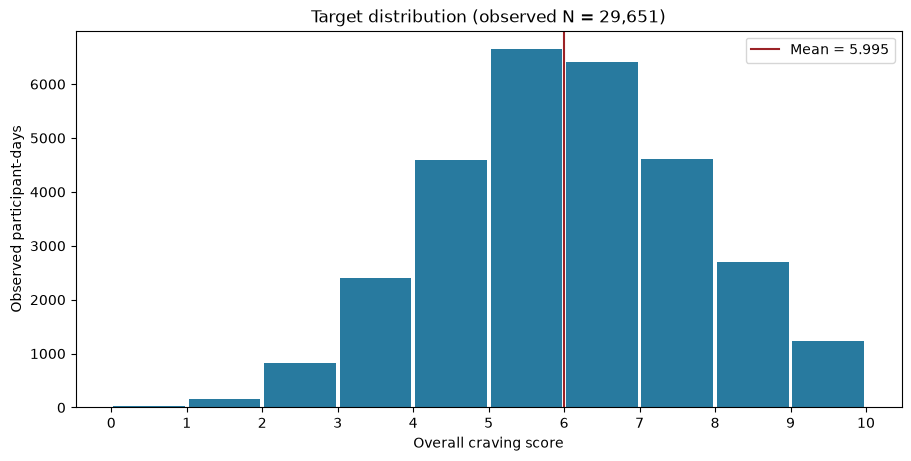

In [8]:
display(pd.Series({key: report["target"][key] for key in
                   ["observed", "missing", "observed_percent", "missing_percent"]}, name="value").to_frame())
display(tables["target_histogram"])
assert int(tables["target_histogram"]["count"].sum()) == observed_n
figure_dir = OUTPUT / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
counts = tables["target_histogram"]["count"].to_numpy()
ax.bar(np.arange(10) + 0.5, counts, width=0.95, color="#287a9f")
ax.axvline(report["target"]["mean"], color="#9b2226", label=f"Mean = {report['target']['mean']:.3f}")
ax.set(xlabel="Overall craving score", ylabel="Observed participant-days", xticks=range(11),
       title=f"Target distribution (observed N = {observed_n:,})")
ax.legend()
fig.savefig(figure_dir / "target_distribution.png", dpi=160)
plt.show()

## 8. Within-person variation and between-person heterogeneity (reference 1.6.1)

For participant $i$, let $N_i$ be its observed target count and
$\bar x_i=\frac{1}{N_i}\sum_{t\in O_i}x_{it}$. Its number of distinct observed
scores detects whether any variation occurs; it does not quantify how much.
The participant summary therefore also reports its sample standard deviation.

The **range of participant means** describes heterogeneity across people.
The **daily mean** pools the available participants at the same within-person
day index. Missingness can change each daily denominator. Nearly constant daily
means can coexist with variable individual trajectories and heterogeneous person
means. The day index is not a shared population calendar date.

,observed,distinct,mean,sample_std
Participant_ID,,,,
P0001,30,22,4.480000,0.706326
P0002,29,16,4.555172,0.625406
P0003,30,18,4.716667,0.641165
P0004,30,15,6.160000,0.442251
P0005,30,16,5.673333,0.585417
P0006,29,15,8.100000,0.486973
P0007,30,14,8.993333,0.558281
P0008,29,22,5.068966,0.776946
P0009,30,19,3.380000,0.650411


,value
status,computed
participants_with_variation,1000
observations_per_person_min,27
observations_per_person_max,30
person_mean_min,1.49
person_mean_max,9.836667
daily_mean_min,5.956535
daily_mean_max,6.043984
potential_adjacent_pairs,29000
valid_adjacent_pairs,28338


,observed,mean,sample_std
Day_Number,,,
1,990,5.987576,1.695386
2,990,5.976465,1.713103
3,988,5.980061,1.679110
4,986,5.970588,1.684346
5,986,6.005882,1.705216
6,993,6.006042,1.661029
7,992,6.001109,1.663064
8,994,5.986620,1.714952
9,993,5.998892,1.672756


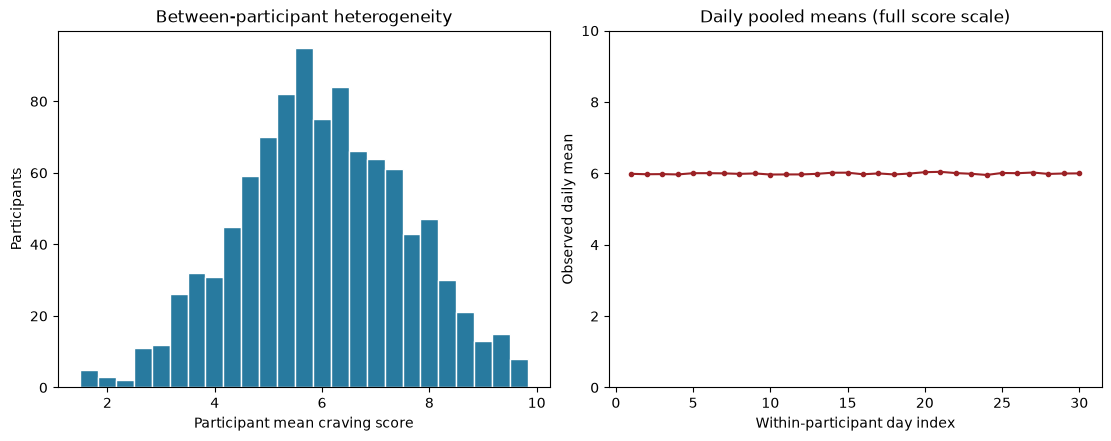

In [9]:
person = tables["participant_target_summary"]
daily = tables["daily_target_summary"]
display(person.head(10))
display(pd.Series(report["longitudinal"]).drop("sum_of_squares").to_frame("value"))
display(daily)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
axes[0].hist(person["mean"], bins=25, color="#287a9f", edgecolor="white")
axes[0].set(xlabel="Participant mean craving score", ylabel="Participants", title="Between-participant heterogeneity")
axes[1].plot(daily.index, daily["mean"], marker=".", color="#9b2226")
axes[1].set(xlabel="Within-participant day index", ylabel="Observed daily mean", title="Daily pooled means (full score scale)", ylim=(0, 10))
fig.savefig(figure_dir / "participant_and_day_means.png", dpi=160)
plt.show()

### Additional decomposition: partition the observed sum of squares

This extension makes the within/between distinction quantitative; it was not a
reported metric in the initial audit. Let $\bar x$ be the mean of all observed
target cells and $d_{it}=x_{it}-\bar x_i$:

$$SS_T=\sum_{i,t\in O_i}(x_{it}-\bar x)^2,$$
$$SS_W=\sum_{i,t\in O_i}d_{it}^2,\qquad
SS_B=\sum_i N_i(\bar x_i-\bar x)^2,\qquad SS_T=SS_W+SS_B.$$

The participant weights $N_i$ matter because target availability differs across
participants. $SS_B/SS_T$ describes the between-person share of observed total
variation. It is **not** an intraclass correlation estimate, a causal attribution,
or a prospective model performance metric. The small residual checks the
algebraic partition and numerical precision.

In [10]:
ss = report["longitudinal"]["sum_of_squares"]
display(pd.Series(ss, name="value").to_frame())
assert math.isclose(ss["total"], ss["within"] + ss["between"], rel_tol=1e-12)

,value
total,84123.580002
within,11485.762799
between,72637.817203
decomposition_residual,-0.0
between_share,0.863466
interpretation,"Descriptive weighted sum-of-squares share, not..."


## 9. Pooled versus person-centered consecutive-day correlation (reference 1.6.1)

Pearson correlation for paired arrays $a_k,b_k$, $k=1,\ldots,K$, is

$$r=\frac{\sum_k(a_k-\bar a)(b_k-\bar b)}
{\sqrt{\sum_k(a_k-\bar a)^2\sum_k(b_k-\bar b)^2}}.$$

Construct a pair only when the same participant has actual days $t$ and $t+1$
**and both target values are observed**. Sorting and shifting after dropping NA
would incorrectly bridge missing observations; pairing different participants
would also be invalid. Complete 30-day keys yield $1{,}000(30-1)=29{,}000$
potential pairs, before excluding missing target endpoints. The number excluded
is not twice the missing target count because adjacent missing cells and boundary
days affect overlapping pairs differently.

- **Pooled:** correlate $x_{it}$ with $x_{i,t+1}$ across valid pairs. Stable
  differences between participants contribute to this coefficient.
- **Person-centered:** first compute $d_{it}=x_{it}-\bar x_i$ using all observed
  values of that participant, then correlate $d_{it}$ with $d_{i,t+1}$ over the
  **same valid pairs**. This is a pooled correlation of deviations, not the
  arithmetic mean of 1,000 separate autocorrelations.

Near-zero centered correlation concerns linear lag-one association under this
centering convention. It does not prove independence, exclude nonlinear or
longer-lag patterns, or measure predictive usefulness. Full-series centering is
descriptive and would use future information if copied into forecasting features.
Estimating person means from short series can itself induce negative dependence
among centered deviations, so a small negative result needs caution.

,Participant_ID,Day_Number,Overall_Craving_Score,next_day,next_value,deviation,next_deviation
0,P0001,1,4.5,2.0,3.9,0.02,-0.58
1,P0001,2,3.9,3.0,5.1,-0.58,0.62
2,P0001,3,5.1,4.0,3.7,0.62,-0.78
3,P0001,4,3.7,5.0,3.9,-0.78,-0.58
4,P0001,5,3.9,6.0,5.8,-0.58,1.32
5,P0001,6,5.8,7.0,3.3,1.32,-1.18
6,P0001,7,3.3,8.0,3.9,-1.18,-0.58
7,P0001,8,3.9,9.0,3.4,-0.58,-1.08
8,P0001,9,3.4,10.0,5.4,-1.08,0.92
9,P0001,10,5.4,11.0,4.8,0.92,0.32


,value
potential_pairs,29000.000000
valid_pairs,28338.000000
pooled_pearson,0.858927
person_centered_pearson,-0.035083


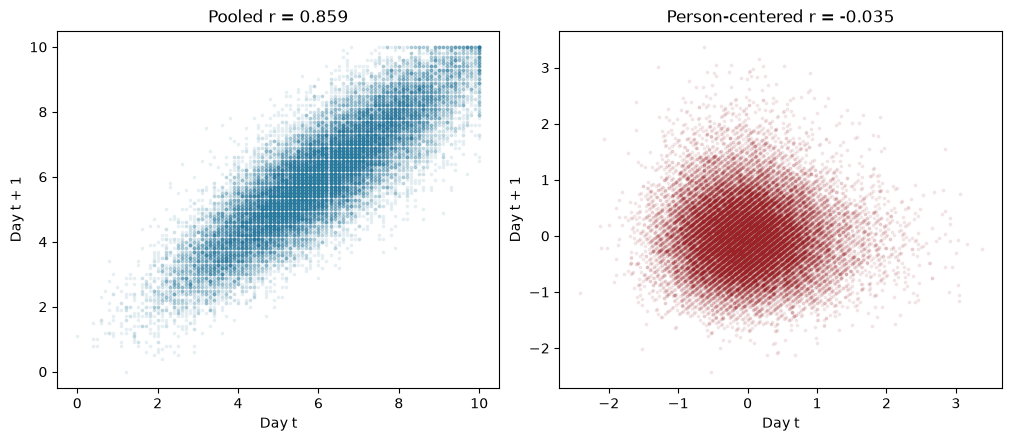

In [11]:
pairs = tables["adjacent_pairs"]
display(pairs.head(10))
assert (pairs["next_day"] == pairs["Day_Number"] + 1).all()
assert pairs[[audit.TARGET, "next_value", "deviation", "next_deviation"]].notna().all().all()

def pearson_from_sums(a, b):
    a, b = np.asarray(a), np.asarray(b)
    a_centered, b_centered = a - a.mean(), b - b.mean()
    return float(np.sum(a_centered * b_centered) / np.sqrt(np.sum(a_centered ** 2) * np.sum(b_centered ** 2)))

pooled = pearson_from_sums(pairs[audit.TARGET], pairs["next_value"])
centered = pearson_from_sums(pairs["deviation"], pairs["next_deviation"])
display(pd.Series({"potential_pairs": report["longitudinal"]["potential_adjacent_pairs"],
                   "valid_pairs": len(pairs), "pooled_pearson": pooled,
                   "person_centered_pearson": centered}, name="value").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), constrained_layout=True)
for ax, a, b, title, color in [
    (axes[0], audit.TARGET, "next_value", f"Pooled r = {pooled:.3f}", "#287a9f"),
    (axes[1], "deviation", "next_deviation", f"Person-centered r = {centered:.3f}", "#9b2226"),
]:
    ax.scatter(pairs[a], pairs[b], s=3, alpha=0.08, color=color, rasterized=True)
    ax.set(xlabel="Day t", ylabel="Day t + 1", title=title)
fig.savefig(figure_dir / "pooled_vs_centered_correlation.png", dpi=160)
plt.show()

## 10. Format, range, category, and profile validity (reference 1.7)

For each rule, report **eligible observed cells** and **flagged cells**. A missing
value is excluded from that rule's eligibility and remains visible in the
missingness table. A rule-violation count sums flagged cells **across rules**;
it is not necessarily a distinct-row count.

- Thirteen score fields: observed values in $[0,10]$ (including peak intensity).
- Thirteen nonscore numeric fields: values at least zero. The reference does not
  enumerate its thirteen fields; this explicit operationalization includes
  `Day_Number` and is documented in `audit.NONNEGATIVE`.
- `First_Pouch_Time`: exact 24-hour `HH:MM` syntax, from `00:00` through `23:59`.
- Three indicators: only `Yes` or `No` when observed.
- Four stable profile fields: checked within each participant in section 4.

Passing these rules means basic internal consistency under the chosen rules.
It does not verify physiological plausibility, clinical validation, an overall
score formula, a complete data dictionary, or a correct simulator.

In [12]:
display(pd.Series({"score_fields": audit.SCORES, "nonnegative_fields": audit.NONNEGATIVE,
                   "binary_fields": audit.BINARY}, name="explicit_rule_scope").to_frame())
display(tables["validity_checks"])
display(tables["inventory"].loc[["First_Pouch_Time", *audit.BINARY], ["categories", "missing"]])

,explicit_rule_scope
score_fields,"[Morning_Cravings_Score, Afternoon_Cravings_Sc..."
nonnegative_fields,"[Day_Number, Nicotine_Use_Duration_Months, Pou..."
binary_fields,"[Attempted_To_Resist_Craving, Successfully_Res..."


,rule,column,eligible,flagged
0,score_in_0_to_10,Morning_Cravings_Score,29631,0
1,score_in_0_to_10,Afternoon_Cravings_Score,29627,0
2,score_in_0_to_10,Evening_Cravings_Score,29654,0
3,score_in_0_to_10,Overall_Craving_Score,29651,0
4,score_in_0_to_10,Daily_Anxiety_Score,30000,0
5,score_in_0_to_10,Morning_Anxiety_Score,30000,0
6,score_in_0_to_10,Evening_Anxiety_Score,29653,0
7,score_in_0_to_10,Perceived_Stress_Score,30000,0
8,score_in_0_to_10,Mood_Score,29658,0
9,score_in_0_to_10,Irritability_Score,30000,0


,categories,missing
column,,
First_Pouch_Time,"[05:00, 05:15, 05:30, 05:45, 06:00, 06:15, 06:...",0
Attempted_To_Resist_Craving,"[No, Yes]",345
Successfully_Resisted,"[No, Yes]",357
Major_Stress_Event_Today,"[No, Yes]",0


## 11. Cross-field semantic flags (reference 1.7.1)

These checks compare fields under **proposed readings of their names**. They
flag questions for the data dictionary rather than automatically identifying
errors. Each percentage states its eligible denominator:

| Check | Eligible rows | Interpretation limit |
| --- | --- | --- |
| Zero daily pouches and first-use time present | Rows with zero pouches | Time could be habitual or scheduled |
| Zero pouches and time-since-last present | Rows with zero pouches | Last use could precede the current day |
| Overall craving above peak | Both scores observed | Their definitions/scales may not be directly comparable |
| Success=Yes with attempt=No | Both indicators observed | An apparent logical conflict under a literal reading |
| Overall missing with all three daily components present | Rows with overall missing | Components do not establish the global-score formula |

No formula for `Overall_Craving_Score` is inferred from column names. Do not
replace a missing overall value with the mean of its components without verified
construction rules. A zero count for one apparent conflict says nothing about
unobserved or unchecked forms of semantic inconsistency.

In [13]:
display(tables["semantic_checks"])
flag = df[audit.TARGET].notna() & df["Craving_Intensity_Peak"].notna() & df[audit.TARGET].gt(df["Craving_Intensity_Peak"])
display(df.loc[flag, [*audit.KEYS, audit.TARGET, "Craving_Intensity_Peak"]].head())

,count,eligible,percent_eligible
check,,,
zero_pouches_with_first_time,358,358,100.000000
zero_pouches_with_time_since_last,355,358,99.162011
overall_above_peak,7078,29651,23.871033
success_without_attempt,0,29299,0.000000
missing_overall_with_complete_components,339,349,97.134670


,Participant_ID,Day_Number,Overall_Craving_Score,Craving_Intensity_Peak
0,P0001,1,4.5,3.9
4,P0001,5,3.9,3.8
7,P0001,8,3.9,3.6
16,P0001,17,5.0,4.7
18,P0001,19,5.7,4.9


## 12. Compare with the original claims and export the calculations

`reference_values.json` contains **299 expectations transcribed from the original
description**, independently of the computed results. Counts, categories, hashes,
and ranges are checked exactly. Rounded means and correlations allow half a unit
in the last published decimal place; this avoids treating publication rounding
as a numerical disagreement. This is reproduction at the published precision,
not a claim that every printed rounded number equals the full-precision value.

The comparison covers structure, thematic counts, historical types, demographics,
published numeric summaries, target bins, longitudinal summaries, missingness,
range-check totals, semantic flags, hashes, and the exhaustive Annex A inventory.
Extra statistics such as every numeric field's variance/IQR and the sum-of-squares
decomposition are labeled extensions and have no invented reference values.

Export machine-readable JSON, tables, and a separate AI-assisted Markdown report.
This does not edit the original description, its provenance claims, the shared
methodology, or the raw data. The standard-library validation script provides a
second calculation route, and the next cell verifies input preservation in this run.

In [14]:
comparison = audit.compare_reference(report)
display(comparison.groupby("section")["passed"].agg(checks="size", passed="sum"))
display(comparison.loc[~comparison["passed"]])
audit.save_results(report, tables, comparison, OUTPUT)
assert comparison["passed"].all(), "Inspect reference disagreements before drawing conclusions."
assert hashlib.sha256(CSV_PATH.read_bytes()).hexdigest() == raw_hash_before
assert hashlib.sha256(audit.ORIGINAL.read_bytes()).hexdigest() == description_hash_before
print(f"{comparison['passed'].sum()}/{len(comparison)} reference claims reproduced at published precision.")
print("Raw CSV and original description hashes are unchanged during this execution.")
print(f"Evidence exported to: {OUTPUT.relative_to(ROOT)}")

,checks,passed
section,,
1.2,15,15
1.3,8,8
1.4,15,15
1.5,60,60
1.6,12,12
1.6.1,10,10
1.7,40,40
1.7.1,5,5
1.9,3,3


,section,metric,expected,actual,absolute_tolerance,passed


299/299 reference claims reproduced at published precision.
Raw CSV and original description hashes are unchanged during this execution.
Evidence exported to: work\andres\dataset_description\dataset_audit_AI_assisted\results


## Interpretation boundaries and methodological references

The CSV supports descriptive calculations. It does not establish a clinical
measurement instrument, the simulator's generating equations, the mechanism of
missingness, causal effects, independent rows, or prediction performance.
The original description remains a historical reference. Existing project
documentation may contain later provenance work; this audit verifies local byte
identity rather than claiming a new verification of Kaggle metadata or licensing.

Primary API references for the explicit computational conventions:

- [Pandas 3 string dtype migration](https://pandas.pydata.org/docs/user_guide/migration-3-strings.html)
- [Sample standard deviation and ddof](https://pandas.pydata.org/docs/reference/api/pandas.Series.std.html)
- [Quantiles and linear interpolation](https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html)
- [Pearson correlation and complete pairs](https://pandas.pydata.org/docs/reference/api/pandas.Series.corr.html)
- [NumPy histogram interval conventions](https://numpy.org/doc/stable/reference/generated/numpy.histogram.html)

All figures use computed values from this execution. They describe the simulated
file; they are not clinical findings or evaluation results from a trained model.